In [1]:
!gdown https://drive.google.com/uc?id=1dXD4MIzHgJ31xVGfDdBx0cgwZs1_W589

Downloading...
From (original): https://drive.google.com/uc?id=1dXD4MIzHgJ31xVGfDdBx0cgwZs1_W589
From (redirected): https://drive.google.com/uc?id=1dXD4MIzHgJ31xVGfDdBx0cgwZs1_W589&confirm=t&uuid=ad9d38d0-12e4-4170-bb05-0f67049c448c
To: /content/rps.zip
100% 321M/321M [00:06<00:00, 47.2MB/s] 


In [2]:
get_ipython().system('unzip rps.zip -d rps')

Archive:  rps.zip
  inflating: rps/README_rpc-cv-images.txt  
  inflating: rps/paper/04l5I8TqdzF9WDMJ.png  
  inflating: rps/paper/0Og76sl5CJhbxWWx.png  
  inflating: rps/paper/0RA9rcrv8iVvuDDU.png  
  inflating: rps/paper/0Uomd0HvOB33m47I.png  
  inflating: rps/paper/0a3UtNzl5Ll3sq8K.png  
  inflating: rps/paper/0cb6cVL8pkfi4wF6.png  
  inflating: rps/paper/0eqArS2GgsBeqgSn.png  
  inflating: rps/paper/0t08v9bAaA0mXGCQ.png  
  inflating: rps/paper/0vugygEjxQJPr9yz.png  
  inflating: rps/paper/0zKU6wEhT2cDe9j0.png  
  inflating: rps/paper/14K62H4KG1hg5qiJ.png  
  inflating: rps/paper/1Dfw5FRlS4h60JPX.png  
  inflating: rps/paper/1Frbe8cdOdkciOBg.png  
  inflating: rps/paper/1Tt9U9SzrOm98Xtw.png  
  inflating: rps/paper/1fKclJk4eBWOQSR1.png  
  inflating: rps/paper/1jHtb93pI8f6pfKo.png  
  inflating: rps/paper/1oKnUgV2CdCaQUUX.png  
  inflating: rps/paper/1uoW7QcH2qAgCTxv.png  
  inflating: rps/paper/1yKjzquSvl9ShK7K.png  
  inflating: rps/paper/1yeoLbmp4alVOtFv.png  
  inflating: rps/p

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import os

In [4]:
import random

SEED = 42
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200,suppress=True)

In [5]:
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [6]:
if torch.cuda.is_available():
    print("CUDA를 사용할 수 있습니다.")
    # 추가적인 CUDA 관련 작업 수행 (예: 장치 설정, 모델을 GPU로 이동)
    # device = torch.device("cuda")
    # model.to(device)
else:
    print("CUDA를 사용할 수 없습니다. CPU를 사용합니다.")

CUDA를 사용할 수 있습니다.


In [7]:
!pwd

/content


In [10]:
!ls rps

paper  README_rpc-cv-images.txt  rock  rps-cv-images  scissors


In [11]:
!ls -R rps/rps-cv-images

rps/rps-cv-images:
paper  README_rpc-cv-images.txt  rock  scissors

rps/rps-cv-images/paper:
04l5I8TqdzF9WDMJ.png  EJ42U85HcmJV7JVm.png  pRZml1c5DSIzYVxA.png
0a3UtNzl5Ll3sq8K.png  EJ7cNnnea5yCEaOd.png  pt2EHjG6vxV6Hjmf.png
0cb6cVL8pkfi4wF6.png  ejC8QIku5jrtci48.png  PTjpGk2rKf6mhx9z.png
0eqArS2GgsBeqgSn.png  eLBTZkvB4E951ml0.png  pUCjvjdpH5HSaWxl.png
0Og76sl5CJhbxWWx.png  eLNpUj2AZ1h4Mrxu.png  pVCqrp8S6Ze3DAI8.png
0RA9rcrv8iVvuDDU.png  em91htnBohvtnG2e.png  pW8TQWh9SoWh0HLE.png
0t08v9bAaA0mXGCQ.png  ePEd8TOzTgrGz5M2.png  PwkqvoT0noMITNaF.png
0Uomd0HvOB33m47I.png  Eq9tohFHMpYXWQZH.png  pwM1GeKjG7KE4i75.png
0vugygEjxQJPr9yz.png  eQaNnPaHwKsOJaYq.png  pYvpGm431tLNheln.png
0zKU6wEhT2cDe9j0.png  et9oIiGQmAgwy7GK.png  PZrfX01MvfB3oeyB.png
14K62H4KG1hg5qiJ.png  EuU83pQABhf4v0AF.png  q35FqG8h9VCDbQ1J.png
1Dfw5FRlS4h60JPX.png  EVtIRpfQ2ys2A3ag.png  Q8idpb4gCSAWs9YH.png
1fKclJk4eBWOQSR1.png  eW9ezZkV7Jxu1BEk.png  QASICiZe79sFTXBz.png
1Frbe8cdOdkciOBg.png  f1aYiLdB5VC3L8Kk.png  Qbn4RJqessetWPHR.p

# 이미지 처리

In [8]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], 
                         std = [0.229,0.224,0.225])
])

train_dataset= datasets.ImageFolder(
    root = 'rps/rps-cv-images',
    transform= transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size =16,
    shuffle = True,
    num_workers = 0
)

#AlexNet 전이학습

In [9]:
import torch.nn as nn
from torchvision import models

model = models.alexnet(weights='DEFAULT')  

for param in model.features.parameters():
    param.requires_grad = False  

model.classifier[6] = nn.Linear(4096, 3)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 192MB/s] 


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=4096, out_features=4096, bias=True)
  (5): ReLU(inplace=True)
  (6): Linear(in_features=4096, out_features=3, bias=True)
)


#학습

In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

num_epochs = 10

history = {
    'epoch' : [],
    'loss' : [],
    'accuracy' : []
}

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total+= labels.size(0)
        correct += (predicted == labels).sum().item()


    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total

    history['epoch'].append(epoch + 1)
    history['loss'].append(epoch_loss)
    history['accuracy'].append(epoch_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%')         

Epoch [1/10], Loss: 0.3790, Accuracy: 94.01%
Epoch [2/10], Loss: 0.1693, Accuracy: 98.13%
Epoch [3/10], Loss: 0.3013, Accuracy: 97.71%
Epoch [4/10], Loss: 0.3247, Accuracy: 98.35%
Epoch [5/10], Loss: 0.1884, Accuracy: 98.90%
Epoch [6/10], Loss: 0.1139, Accuracy: 99.27%
Epoch [7/10], Loss: 0.1070, Accuracy: 99.45%
Epoch [8/10], Loss: 0.2475, Accuracy: 98.77%
Epoch [9/10], Loss: 0.0825, Accuracy: 99.63%
Epoch [10/10], Loss: 0.3641, Accuracy: 99.04%


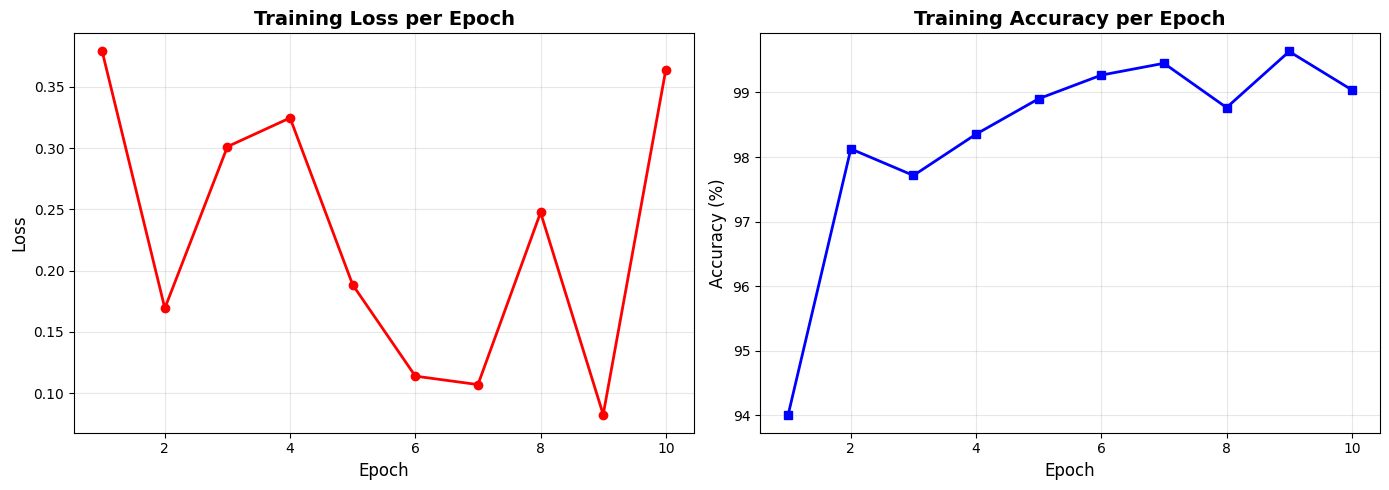

In [13]:
# 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss 그래프
axes[0].plot(history['epoch'], history['loss'], marker='o', color='red', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training Loss per Epoch', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Accuracy 그래프
axes[1].plot(history['epoch'], history['accuracy'], marker='s', color='blue', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy (%)', fontsize=12)
axes[1].set_title('Training Accuracy per Epoch', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
class_names = ['paper','rock','scissors']
model.eval()

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [17]:
import glob
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report

all_predictions = []
all_labels = []
all_images = []
sample_images = {'paper': [], 'rock': [], 'scissors': []}
sample_preds = {'paper': [], 'rock': [], 'scissors': []}

folders = ['paper', 'rock', 'scissors']
class_to_idx = {'paper': 0, 'rock': 1, 'scissors': 2}

with torch.no_grad():
    for folder in folders:
        folder_path = f'rps/{folder}'
        image_files = glob.glob(f'{folder_path}/*.png')
        
        print(f'\n{folder} 폴더: {len(image_files)}개 이미지 처리 중...')

        for img_path in image_files:
            img = Image.open(img_path).convert('RGB')
            img_tensor = transform(img).unsqueeze(0).to(device)

            output = model(img_tensor)
            _, pred = torch.max(output, 1)

            all_predictions.append(pred.item())
            all_labels.append(class_to_idx[folder])

            if len(sample_images[folder]) < 6:
                sample_images[folder].append(img)
                sample_preds[folder].append(pred.item())



paper 폴더: 712개 이미지 처리 중...

rock 폴더: 726개 이미지 처리 중...

scissors 폴더: 750개 이미지 처리 중...



Total Acc: 99.13%

Confusion Matrix:
[[693  15   4]
 [  0 726   0]
 [  0   0 750]]


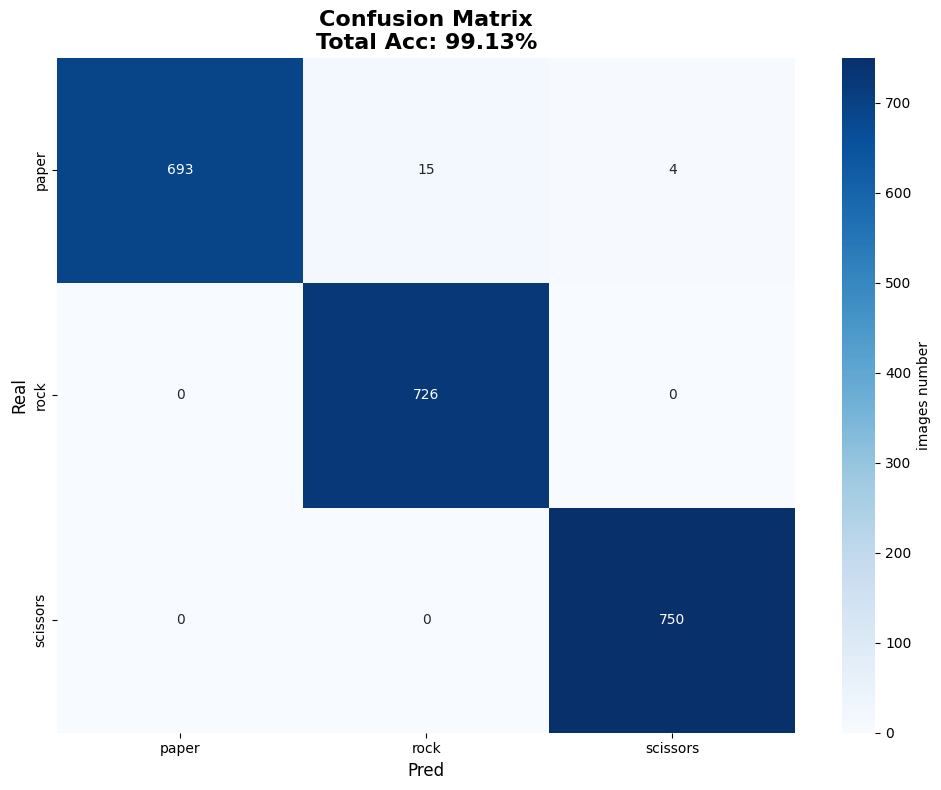

In [19]:
# Confusion Matrix 생성
cm = confusion_matrix(all_labels, all_predictions)
accuracy = np.sum(np.array(all_predictions) == np.array(all_labels)) / len(all_labels) * 100

print(f'\nTotal Acc: {accuracy:.2f}%')
print('\nConfusion Matrix:')
print(cm)

# 시각화 1: Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'images number'})
plt.title(f'Confusion Matrix\nTotal Acc: {accuracy:.2f}%', fontsize=16, fontweight='bold')
plt.ylabel('Real', fontsize=12)
plt.xlabel('Pred', fontsize=12)
plt.tight_layout()
plt.show()

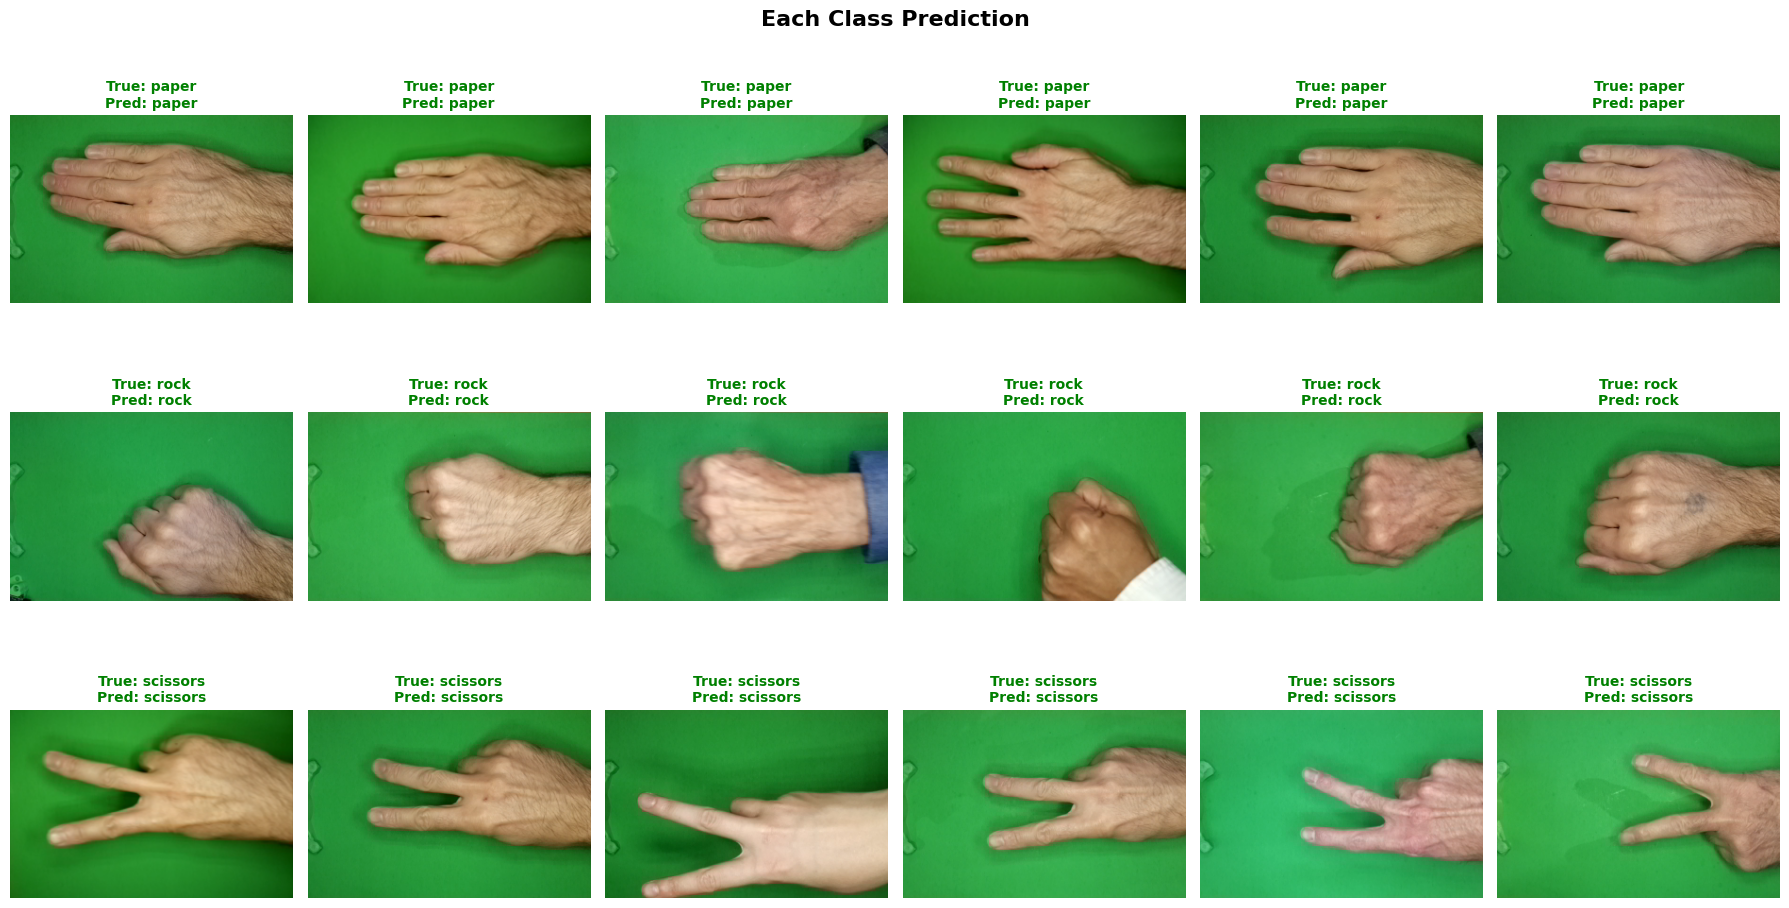

In [21]:
# 시각화 2: 각 클래스별 샘플 이미지와 예측 결과
fig, axes = plt.subplots(3, 6, figsize=(18, 10))

for idx, folder in enumerate(folders):
    for j in range(6):
        ax = axes[idx, j]
        if j < len(sample_images[folder]):
            ax.imshow(sample_images[folder][j])
            pred_class = class_names[sample_preds[folder][j]]
            true_class = folder
            
            # 정답이면 초록색, 오답이면 빨간색
            color = 'green' if pred_class == true_class else 'red'
            ax.set_title(f'True: {true_class}\nPred: {pred_class}', 
                        color=color, fontsize=10, fontweight='bold')
        ax.axis('off')

plt.suptitle('Each Class Prediction', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

paper acc: 97.33% (693/712)
rock acc: 100.00% (726/726)
scissors acc: 100.00% (750/750)


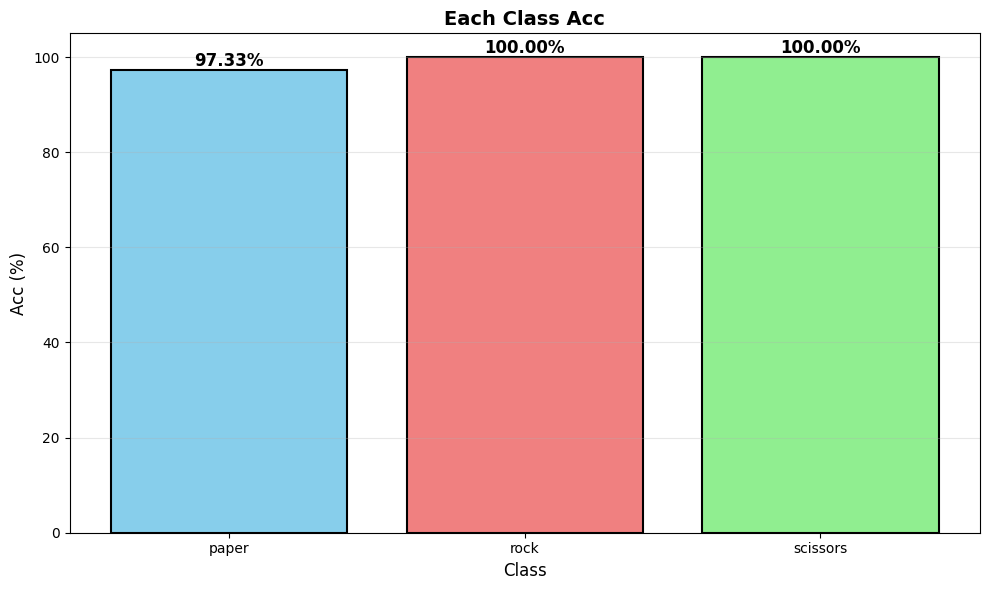

In [22]:
# 시각화 3: 클래스별 정확도 바 차트
class_accuracies = []
for i, folder in enumerate(folders):
    class_correct = np.sum((np.array(all_labels) == i) & (np.array(all_predictions) == i))
    class_total = np.sum(np.array(all_labels) == i)
    class_acc = class_correct / class_total * 100 if class_total > 0 else 0
    class_accuracies.append(class_acc)
    print(f'{folder} acc: {class_acc:.2f}% ({class_correct}/{class_total})')

plt.figure(figsize=(10, 6))
bars = plt.bar(class_names, class_accuracies, color=['skyblue', 'lightcoral', 'lightgreen'], 
               edgecolor='black', linewidth=1.5)
plt.ylabel('Acc (%)', fontsize=12)
plt.xlabel('Class', fontsize=12)
plt.title('Each Class Acc', fontsize=14, fontweight='bold')
plt.ylim(0, 105)

# 각 바 위에 정확도 표시
for bar, acc in zip(bars, class_accuracies):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
            f'{acc:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
from google.colab import runtime
runtime.unassign()